In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn.datasets as datasets
import sklearn.metrics as mt
import pandas as pd
import pickle
import seaborn as sns

## Dataset

In [2]:
x, y = datasets.make_moons(n_samples = 500, noise = 0.05)

In [3]:
print(f'{x.shape = }, {y.shape = }')

x.shape = (500, 2), y.shape = (500,)


In [4]:
pd.DataFrame({'x_1' : x[:,0], 'x_2' : x[:,1], 'y' : y})

,x_1,x_2,y
0,1.943132,0.332668,1
1,-0.892171,0.269543,0
2,1.561974,-0.313246,1
3,1.596803,-0.352107,1
4,0.943858,-0.048942,0
...,...,...,...
495,1.932940,0.100202,1
496,1.280246,-0.461593,1
497,0.881549,0.368353,0
498,1.389395,-0.362904,1


In [5]:
unique = np.unique(y, return_counts = True)
for label, qtd_label in zip(unique[0], unique[1]):
    print(f'Label: {label}\t Counts: {qtd_label}')

Label: 0	 Counts: 250
Label: 1	 Counts: 250


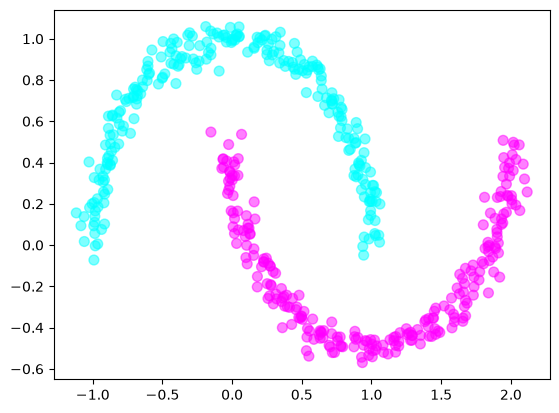

In [6]:
plt.scatter(x[:,0], x[:,1], c = y, s = 50, alpha=0.5, cmap='cool')

## Modelo

- Inicialização dos pesos e bias
- Feedforward
- Cálculo de perda
- Backpropagation
 - Fit

In [7]:
import numpy as np

class NnModel:
    def __init__(self, x: np.ndarray, y: np.ndarray, hidden_neurons: int = 10, output_neurons: int = 2):
        np.random.seed(8)
        self.x = x
        self.y = y
        self.hidden_neurons = hidden_neurons
        self.output_neurons = output_neurons
        self.input_neurons = self.x.shape[1]

        # Inicializa os pesos e bias (Xavier Initialization)
        self.W1 = np.random.randn(self.input_neurons, self.hidden_neurons) / np.sqrt(self.input_neurons)
        self.B1 = np.zeros((1, self.hidden_neurons))
        self.W2 = np.random.randn(self.hidden_neurons, self.output_neurons) / np.sqrt(self.hidden_neurons) 
        self.B2 = np.zeros((1, self.output_neurons))
        self.model_dict = {'W1': self.W1, 'B1': self.B1, 'W2': self.W2, 'B2': self.B2}
        self.z1 = 0
        self.f1 = 0

    def forward(self, x: np.ndarray) -> np.ndarray:
        # Equação da reta (1)
        self.z1 = x.dot(self.W1) + self.B1

        # Função de ativação (1)
        self.f1 = np.tanh(self.z1)

        # Equação da reta (2)
        z2 = self.f1.dot(self.W2) + self.B2

        # Softmax
        exp_values = np.exp(z2)
        softmax = exp_values / np.sum(exp_values, axis=1, keepdims=True)
        return softmax

    def loss(self, softmax):
        # Cross Entropy
        predictions = np.zeros(self.y.shape[0])
        for i, correct_index in enumerate(self.y):
            predictions[i] = softmax[i][correct_index]

        # CORREÇÃO: Somar o log de todas as predições em vez de pegar apenas a última iteração do loop
        log_prob = np.sum(-np.log(predictions))
        return log_prob / self.y.shape[0]

    def backpropagation(self, softmax: np.ndarray, learning_rate: float) -> None:
        delta2 = np.copy(softmax)
        delta2[range(self.x.shape[0]), self.y] -= 1
        
        dW2 = (self.f1.T).dot(delta2)
        dB2 = np.sum(delta2, axis=0, keepdims=True)
        
        delta1 = delta2.dot(self.W2.T) * (1 - np.power(np.tanh(self.z1), 2))
        dW1 = (self.x.T).dot(delta1)
        dB1 = np.sum(delta1, axis=0, keepdims=True)
        
        # Atualização dos pesos e bias
        self.W1 += -learning_rate * dW1
        self.W2 += -learning_rate * dW2
        self.B1 += -learning_rate * dB1
        self.B2 += -learning_rate * dB2

    def show_plt(self, predictions):
        if self.x.shape[1] != 2:
            return

        plt.scatter(self.x[:,0], self.x[:,1], s = 50, c = predictions, cmap='cool', alpha=0.7)
        plt.show()


    # CORREÇÃO: Indentação alinhada para pertencer à classe NnModel
    def fit(self, epochs: int, lr: float):

        for epoch in range(epochs):

            outputs = self.forward(self.x)
            loss = self.loss(outputs)
            self.backpropagation(softmax=outputs, learning_rate=lr)

            # CORREÇÃO: Utilizar self.y no lugar de y
            prediction = np.argmax(outputs, axis=1)
            correct = (prediction == self.y).sum()
            accuracy = correct / self.y.shape[0]
            

            if int((epoch + 1) % (epochs / 10)) == 0:
                print(f'Epoch: [{epoch + 1} / {epochs}] Accuracy: {accuracy:.3f} Loss: {loss:.5f}')
        
        # CORREÇÃO: O return deve ficar dentro do método fit
        return prediction

# Testando o modelo fora da classe
# Supondo que x e y já estejam definidos previamente
# model = NnModel(x, y, hidden_neurons=10, output_neurons=2)
# result = model.fit(epochs=1000, lr=0.01)

In [8]:
hidden_neurons = 10
output_neurons = 2
learning_rate = 0.001
epochs = 100

In [9]:
model = NnModel(x, y, hidden_neurons=hidden_neurons, output_neurons=output_neurons)
result = model.fit(epochs=epochs, lr=learning_rate)

Epoch: [10 / 100] Accuracy: 0.782 Loss: 0.42293
Epoch: [20 / 100] Accuracy: 0.854 Loss: 0.32747
Epoch: [30 / 100] Accuracy: 0.882 Loss: 0.27774
Epoch: [40 / 100] Accuracy: 0.892 Loss: 0.25065
Epoch: [50 / 100] Accuracy: 0.900 Loss: 0.23236
Epoch: [60 / 100] Accuracy: 0.904 Loss: 0.21735
Epoch: [70 / 100] Accuracy: 0.910 Loss: 0.20346
Epoch: [80 / 100] Accuracy: 0.918 Loss: 0.18988
Epoch: [90 / 100] Accuracy: 0.926 Loss: 0.17640
Epoch: [100 / 100] Accuracy: 0.932 Loss: 0.16312


## Testes e resultados


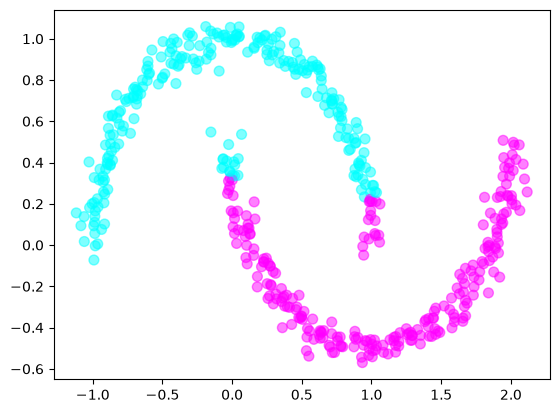

In [10]:
plt.scatter(x[:,0], x[:,1], c = result, s = 50, alpha=0.5, cmap='cool')

## Cluster Dataset


In [11]:
x_, y_ = datasets.make_blobs(n_samples=400, n_features=2, centers=4, random_state=10, cluster_std=0.9, shuffle=True)

In [12]:
x_.shape, y_.shape

((400, 2), (400,))

In [13]:
np.unique(y_, return_counts=True)

(array([0, 1, 2, 3]), array([100, 100, 100, 100]))

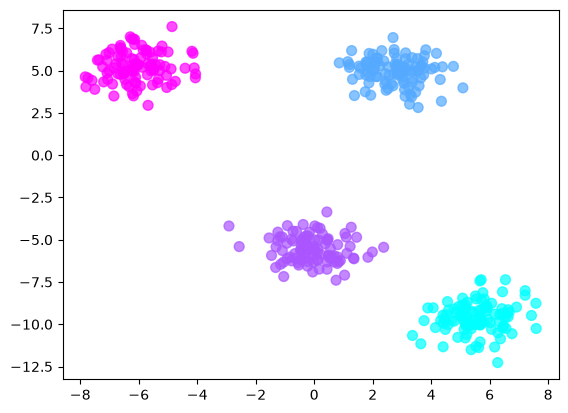

In [14]:
plt.scatter(x_[:,0], x_[:,1], s = 50, c = y_, cmap='cool', alpha=0.7)

In [15]:
hidden_neurons = 15
output_neurons = 4
learning_rate = 0.002
epochs = 50

In [16]:
model = NnModel(x_, y_, hidden_neurons=hidden_neurons, output_neurons=output_neurons)
result = model.fit(epochs=1000, lr=0.0001)

Epoch: [100 / 1000] Accuracy: 0.988 Loss: 0.09807
Epoch: [200 / 1000] Accuracy: 0.995 Loss: 0.05688
Epoch: [300 / 1000] Accuracy: 0.993 Loss: 0.04292
Epoch: [400 / 1000] Accuracy: 0.993 Loss: 0.03604
Epoch: [500 / 1000] Accuracy: 0.993 Loss: 0.03181
Epoch: [600 / 1000] Accuracy: 0.993 Loss: 0.02887
Epoch: [700 / 1000] Accuracy: 0.993 Loss: 0.02667
Epoch: [800 / 1000] Accuracy: 0.993 Loss: 0.02494
Epoch: [900 / 1000] Accuracy: 0.993 Loss: 0.02356
Epoch: [1000 / 1000] Accuracy: 0.993 Loss: 0.02245


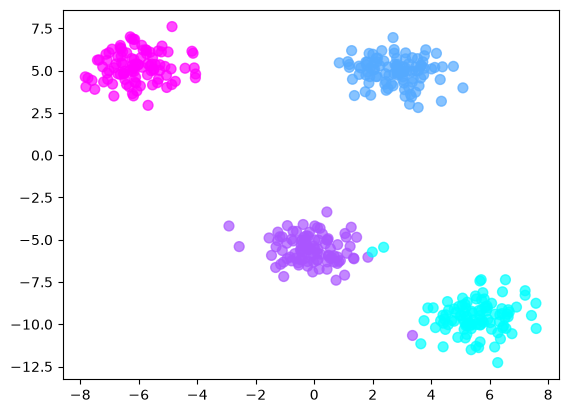

In [17]:
plt.scatter(x_[:,0], x_[:,1], s = 50, c = result, cmap='cool', alpha=0.7)

## 3D


In [18]:
x_, y_ = datasets.make_blobs(n_samples=400, n_features=3, centers=4, random_state=50, cluster_std=0.9, shuffle=True)

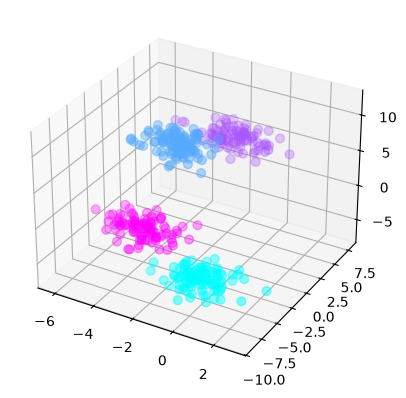

In [19]:
ax = plt.axes(projection = '3d')
ax.scatter3D(x_[:,0], x_[:,1],x_[:,2], s = 40, c = y_, cmap='cool', alpha=0.7)

In [20]:
modelo3d = NnModel(x_, y_, hidden_neurons=10, output_neurons=4)
resultado3d = modelo3d.fit(epochs=50, lr=0.001)

Epoch: [5 / 50] Accuracy: 0.995 Loss: 0.31690
Epoch: [10 / 50] Accuracy: 1.000 Loss: 0.14834
Epoch: [15 / 50] Accuracy: 1.000 Loss: 0.09511
Epoch: [20 / 50] Accuracy: 1.000 Loss: 0.07015
Epoch: [25 / 50] Accuracy: 1.000 Loss: 0.05575
Epoch: [30 / 50] Accuracy: 1.000 Loss: 0.04638
Epoch: [35 / 50] Accuracy: 1.000 Loss: 0.03980
Epoch: [40 / 50] Accuracy: 1.000 Loss: 0.03493
Epoch: [45 / 50] Accuracy: 1.000 Loss: 0.03117
Epoch: [50 / 50] Accuracy: 1.000 Loss: 0.02818


## Novo dataframe

In [21]:
df = datasets.load_breast_cancer(as_frame=True)

In [22]:
df.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [23]:
print(df.DESCR)

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [24]:
df['data'].head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [25]:
np.unique(df.target, return_counts=True), df.target_names

((array([0, 1]), array([212, 357])),
 array(['malignant', 'benign'], dtype='<U9'))

In [26]:
for target, target_name in zip(np.unique(df.target), df.target_names):
    print(f'Classe: {target}\t Nome: {target_name}')

Classe: 0	 Nome: malignant
Classe: 1	 Nome: benign


In [27]:
df.data.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

In [28]:
x_bc = df.data.to_numpy()[:, 4:9]
y_bc = df.target.to_numpy()

In [29]:
x_bc.shape, y_bc.shape

((569, 5), (569,))

In [30]:
bc = NnModel(x = x_bc, y = y_bc, hidden_neurons = 8, output_neurons = 2)
result_bc = bc.fit(epochs = 2000, lr = 0.0003)

Epoch: [200 / 2000] Accuracy: 0.808 Loss: 0.46182
Epoch: [400 / 2000] Accuracy: 0.873 Loss: 0.34624
Epoch: [600 / 2000] Accuracy: 0.895 Loss: 0.32059
Epoch: [800 / 2000] Accuracy: 0.895 Loss: 0.30899
Epoch: [1000 / 2000] Accuracy: 0.896 Loss: 0.30009
Epoch: [1200 / 2000] Accuracy: 0.896 Loss: 0.29206
Epoch: [1400 / 2000] Accuracy: 0.900 Loss: 0.28453
Epoch: [1600 / 2000] Accuracy: 0.902 Loss: 0.27740
Epoch: [1800 / 2000] Accuracy: 0.903 Loss: 0.27065
Epoch: [2000 / 2000] Accuracy: 0.910 Loss: 0.26429


In [31]:
print(mt.classification_report(y_bc, result_bc))

              precision    recall  f1-score   support

           0       0.92      0.83      0.87       212
           1       0.91      0.96      0.93       357

    accuracy                           0.91       569
   macro avg       0.91      0.90      0.90       569
weighted avg       0.91      0.91      0.91       569



<Axes: >

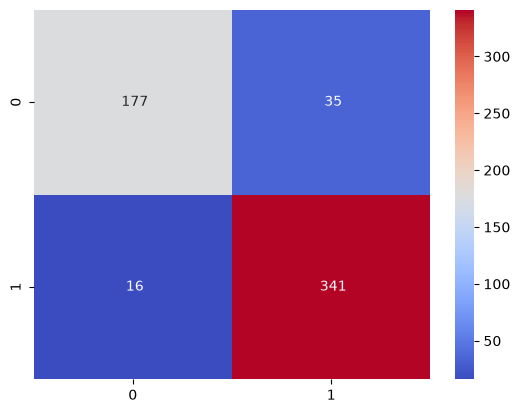

In [32]:
confusion_matrix = mt.confusion_matrix (y_bc, result_bc)
sns.heatmap(confusion_matrix, annot=True, cmap='coolwarm', fmt=' .0f')

In [35]:
# Criar o modelo salvo
with open('modelo_treinado.pickle', 'wb') as f:
    pickle.dump(bc, f)

In [38]:
# Carregar o modelo salvo
with open('modelo_treinado.pickle', 'rb') as f:
    modelo_carregado = pickle.load(f)

In [39]:
modelo_carregado.model_dict

{'W1': array([[ 0.13476662,  0.50527106, -0.76832669, -0.85071557, -0.77895049,
          1.2636577 ,  0.54562854,  0.89982029],
        [ 0.58167068,  0.52409429, -0.40167124,  0.38781524, -0.29751046,
          0.12706875, -0.65929074, -0.49984769],
        [ 0.02632713, -0.00944484, -0.71315968,  1.21680089, -1.82158399,
         -1.15460298,  1.08757945,  0.6525775 ],
        [-1.48071836, -0.2233269 , -0.71711649,  2.57195215, -2.78198029,
         -1.82165034,  2.63014214,  0.64569122],
        [ 0.0990587 ,  0.10230617,  0.06567851, -0.40495512,  0.30822949,
         -0.37182544, -0.40370087, -0.26389804]]),
 'B1': array([[ 0.09175862, -0.007771  ,  0.2747632 , -0.07652178,  0.19513303,
          0.10142306, -0.16667557, -0.19533931]]),
 'W2': array([[-1.11240421,  0.81194103],
        [-0.18500739,  0.2625206 ],
        [-0.55379491,  0.69352096],
        [ 2.4104254 , -1.4529591 ],
        [-2.63748107,  1.93200549],
        [-2.1547278 ,  0.86464245],
        [ 1.78863459, -2

In [44]:
np.round(modelo_carregado.forward(np.array([0.085, 0.064, 0.15, 0.21, 0.078])), 3)

array([[0.999, 0.001]])